In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
import time
from pathlib import Path

import dask
import numpy as np
import pandas as pd
import xarray as xr
from dask.diagnostics import ProgressBar

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid", {"grid.color": ".93"})

from src.data_processing.load_data import ClimateReanalysisData
from src.utils.constants import REFERENCE_PERIOD
from src.conversion_energy.wind import extrapolate_wind_speed

In [3]:
with open("../../paths_so4.json") as f:
    paths = json.load(f)

path_data_cerra = Path(paths["path_data_cerra"])
path_data_processed = Path(paths["path_data_processed"])

ws_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "ws.zarr"
ws_10m_cerra_path = path_data_processed / "cerra_processed" / "regridded" / "10si.zarr"
ws_alpha_cerra_path = path_data_processed / "cerra_processed" / "alpha"

In [4]:
ds_ws = ClimateReanalysisData(
    ws_cerra_path,
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_ws.ds_data = ds_ws.ds_data.sel(time=slice(*REFERENCE_PERIOD))

ds_ws_10m = ClimateReanalysisData(
    ws_10m_cerra_path,
    chunks="auto",
    extent=None,
    load=False,
    drop_leap_days=True,
)
ds_ws_10m.ds_data = ds_ws_10m.ds_data.sel(time=slice(*REFERENCE_PERIOD)).rename({"10si": "ws"})

In [5]:
heights = [10, 100]

da_alpha_cerra = xr.open_dataset(ws_alpha_cerra_path / f"da_alpha_cerra_heights_{heights[0]}_{heights[1]}.nc")
da_alpha_temp_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path / f"da_alpha_temp_smoothed_cerra_heights_{heights[0]}_{heights[1]}.nc"
)
da_alpha_tempspatial_smoothed_cerra = xr.open_dataset(
    ws_alpha_cerra_path / f"da_alpha_tempspatial_smoothed_cerra_heights_{heights[0]}_{heights[1]}.nc"
)

# Comparison of the different alphas

## First timestep

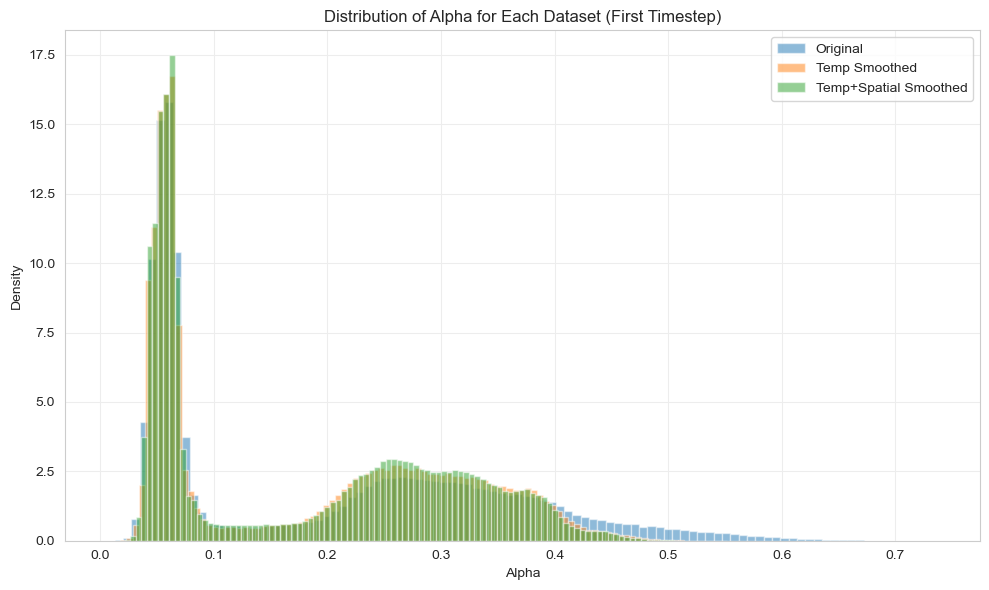

In [6]:
# Extract alpha values for the first timestep and flatten
alpha_samples = {
    "Original": da_alpha_cerra.alpha.isel(time=0).values.ravel(),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.isel(time=0).values.ravel(),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.isel(
        time=0
    ).values.ravel(),
}

plt.figure(figsize=(10, 6))
for label, data in alpha_samples.items():
    plt.hist(data, bins=100, alpha=0.5, label=label, density=True)

plt.xlabel("Alpha")
plt.ylabel("Density")
plt.title("Distribution of Alpha for Each Dataset (First Timestep)")
plt.legend()
plt.tight_layout()
plt.show()

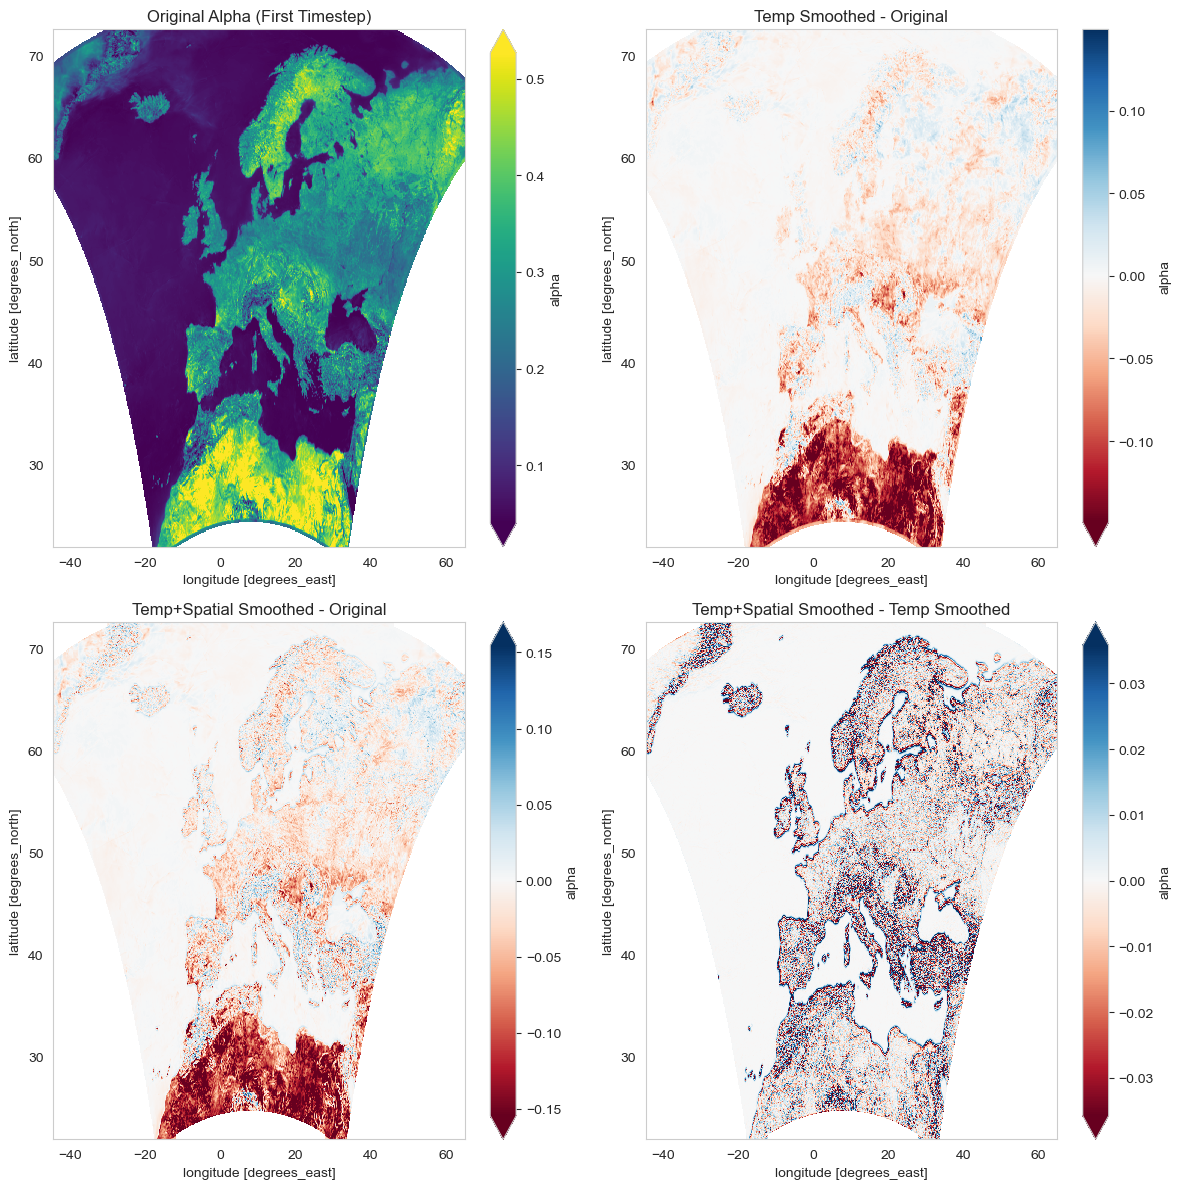

In [7]:
# Plot the map of the original alpha (first timestep)
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

# Original alpha
da_alpha_cerra.alpha.isel(time=0).plot(ax=axes[0], cmap="viridis", robust=True)
axes[0].set_title("Original Alpha (First Timestep)")

# Difference: Temp Smoothed - Original
(
    da_alpha_temp_smoothed_cerra.alpha.isel(time=0) - da_alpha_cerra.alpha.isel(time=0)
).plot(ax=axes[1], cmap="RdBu", robust=True)
axes[1].set_title("Temp Smoothed - Original")

# Difference: Temp+Spatial Smoothed - Original
(
    da_alpha_tempspatial_smoothed_cerra.alpha.isel(time=0)
    - da_alpha_cerra.alpha.isel(time=0)
).plot(ax=axes[2], cmap="RdBu", robust=True)
axes[2].set_title("Temp+Spatial Smoothed - Original")

# Difference: Temp+Spatial Smoothed - Temp Smoothed
(
    da_alpha_tempspatial_smoothed_cerra.alpha.isel(time=0)
    - da_alpha_temp_smoothed_cerra.alpha.isel(time=0)
).plot(ax=axes[3], cmap="RdBu", robust=True)
axes[3].set_title("Temp+Spatial Smoothed - Temp Smoothed")

plt.tight_layout()
plt.show()

## General analysis

### Variability

In [ ]:
# Temporal variability: standard deviation over time for each grid point
temporal_std = {
    "Original": da_alpha_cerra.alpha.std(dim="time"),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.std(dim="time"),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.std(dim="time"),
}

# Spatial variability: standard deviation over space for each timestep
spatial_std = {
    "Original": da_alpha_cerra.alpha.std(dim=["lat", "lon"]),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.std(dim=["lat", "lon"]),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.std(dim=["lat", "lon"]),
}

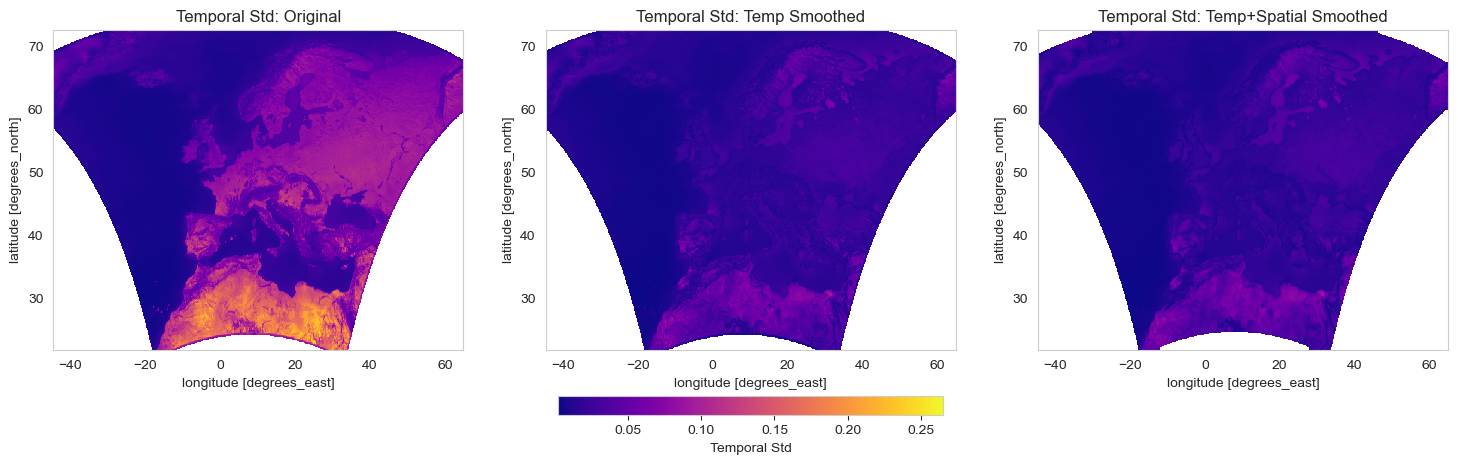

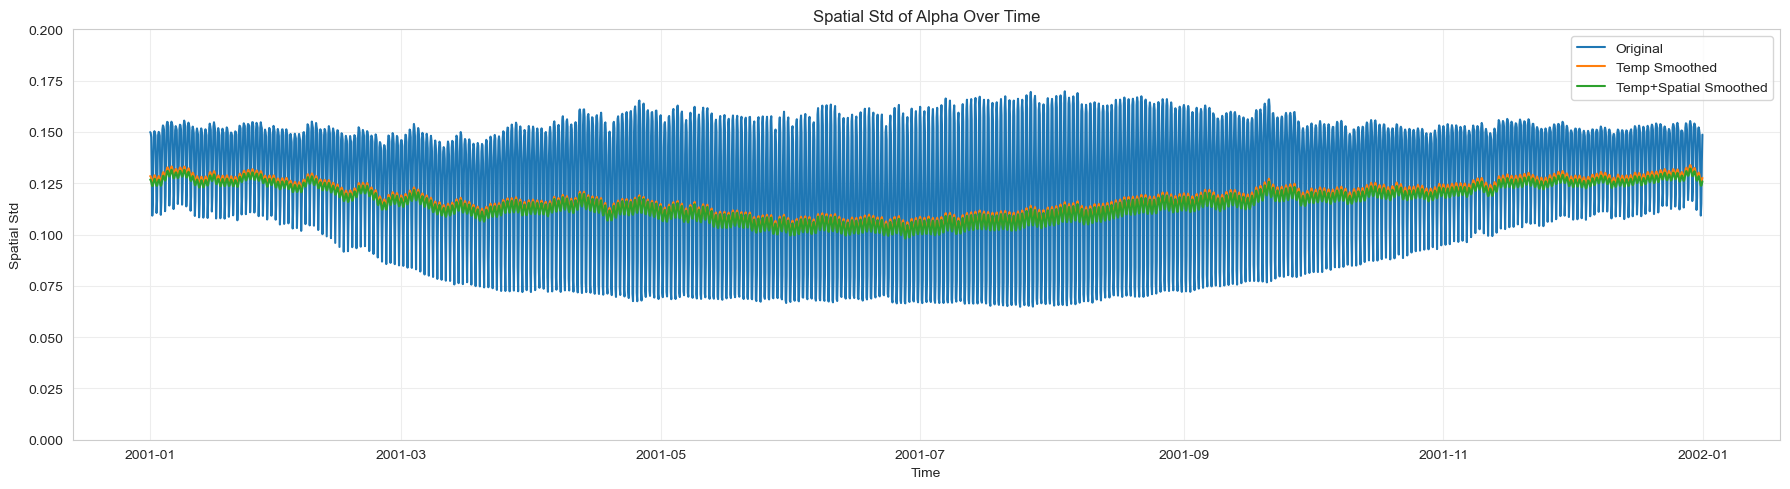

In [12]:
# Plot temporal std maps for each dataset with a shared colorbar and same value range
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(std_map.min().item() for std_map in temporal_std.values())
vmax = max(std_map.max().item() for std_map in temporal_std.values())

im_list = []
for ax, (label, std_map) in zip(axes, temporal_std.items()):
    im = std_map.plot(ax=ax, cmap="plasma", robust=True, vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.set_title(f"Temporal Std: {label}")
    im_list.append(im)

# Add a single colorbar for all subplots, place it below the subplots (horizontal)
cbar = fig.colorbar(im_list[0], ax=axes, orientation='horizontal', fraction=0.05, pad=0.12)
cbar.set_label("Temporal Std")

# plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

# Plot spatial std time series for each dataset
plt.figure(figsize=(18, 5))
for label, std_ts in spatial_std.items():
    plt.plot(da_alpha_cerra.time, std_ts, label=label)
plt.xlabel("Time")
plt.ylabel("Spatial Std")
plt.ylim(0, 0.2)
plt.title("Spatial Std of Alpha Over Time")
plt.legend()
plt.tight_layout()
plt.show()

### Mean

In [6]:
# Compute spatial mean (mean over time for each grid point)
spatial_mean = {
    "Original": da_alpha_cerra.alpha.mean(dim="time"),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.mean(dim="time"),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.mean(dim="time"),
}

# Compute temporal mean (mean over space for each timestep)
temporal_mean = {
    "Original": da_alpha_cerra.alpha.mean(dim=["lat", "lon"]),
    "Temp Smoothed": da_alpha_temp_smoothed_cerra.alpha.mean(dim=["lat", "lon"]),
    "Temp+Spatial Smoothed": da_alpha_tempspatial_smoothed_cerra.alpha.mean(dim=["lat", "lon"]),
}

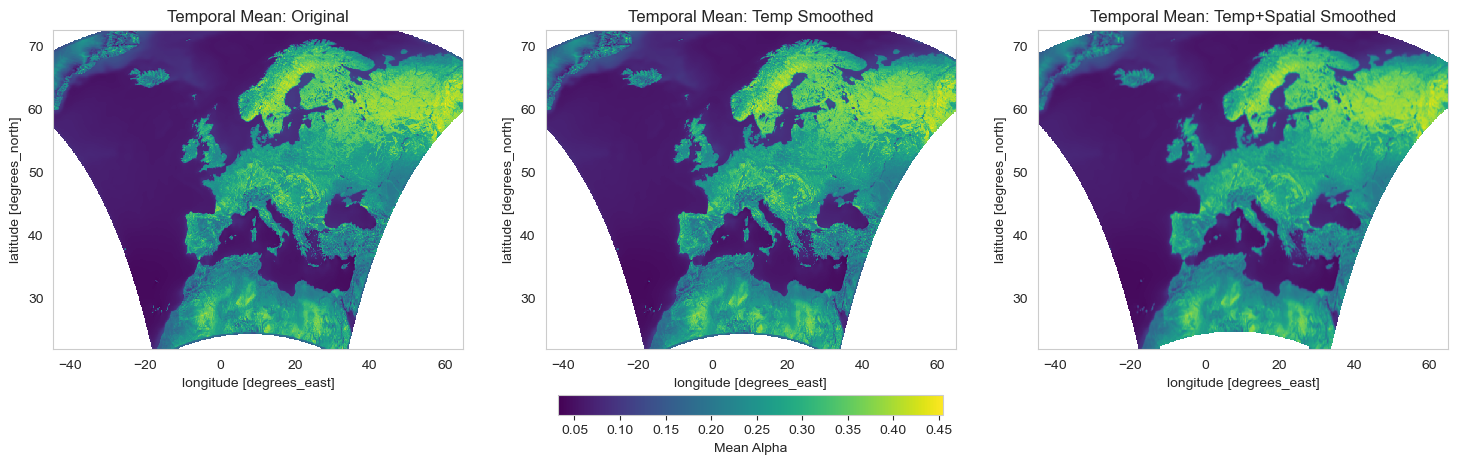

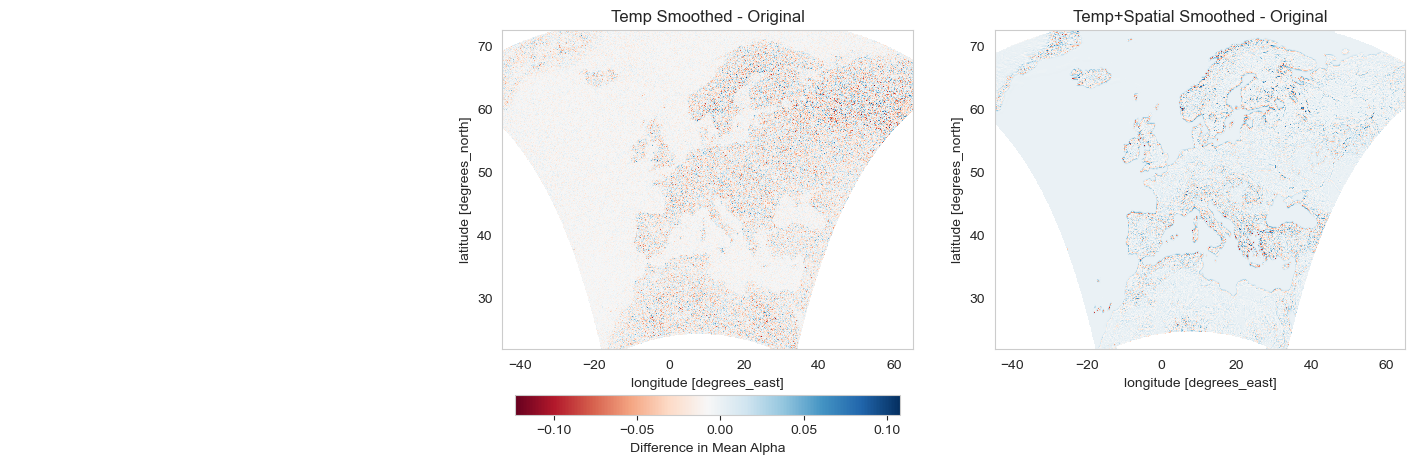

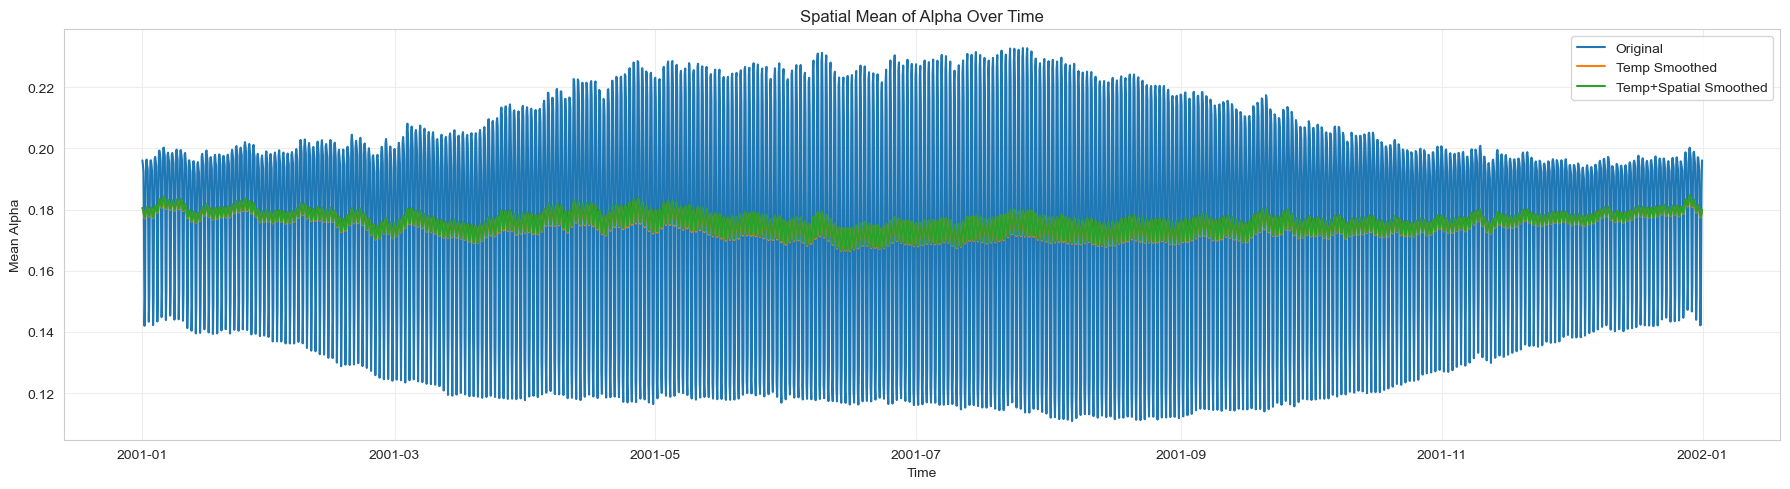

In [10]:
# Plot spatial mean maps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vmin = min(mean_map.min().item() for mean_map in spatial_mean.values())
vmax = max(mean_map.max().item() for mean_map in spatial_mean.values())

im_list = []
for ax, (label, mean_map) in zip(axes, spatial_mean.items()):
    im = mean_map.plot(ax=ax, cmap="viridis", robust=True, vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.set_title(f"Temporal Mean: {label}")
    im_list.append(im)

cbar = fig.colorbar(im_list[0], ax=axes, orientation='horizontal', fraction=0.05, pad=0.12)
cbar.set_label("Mean Alpha")
plt.show()
# Plot difference in spatial mean between original and smoothed versions
fig_diff, axes_diff = plt.subplots(1, 3, figsize=(18, 5))

# First subplot: empty (for alignment)
axes_diff[0].axis("off")

# Second subplot: Temp Smoothed - Original
diff_temp = spatial_mean["Temp Smoothed"] - spatial_mean["Original"]
im_temp = diff_temp.plot(ax=axes_diff[1], cmap="RdBu", robust=True,
                        vmin=diff_temp.min().item(), vmax=diff_temp.max().item(), add_colorbar=False)
axes_diff[1].set_title("Temp Smoothed - Original")

# Third subplot: Temp+Spatial Smoothed - Original
diff_tempspatial = spatial_mean["Temp+Spatial Smoothed"] - spatial_mean["Original"]
im_tempspatial = diff_tempspatial.plot(ax=axes_diff[2], cmap="RdBu", robust=True,
                                       vmin=diff_tempspatial.min().item(), vmax=diff_tempspatial.max().item(), add_colorbar=False)
axes_diff[2].set_title("Temp+Spatial Smoothed - Original")

# Add a single colorbar for both difference plots
cbar_diff = fig_diff.colorbar(im_tempspatial, ax=axes_diff, orientation='horizontal', fraction=0.05, pad=0.12)
cbar_diff.set_label("Difference in Mean Alpha")
plt.show()

# Plot temporal mean time series
plt.figure(figsize=(18, 5))
for label, mean_ts in temporal_mean.items():
    plt.plot(da_alpha_cerra.time, mean_ts, label=label)
plt.xlabel("Time")
plt.ylabel("Mean Alpha")
plt.title("Spatial Mean of Alpha Over Time")
plt.legend()
plt.tight_layout()
plt.show()

### Boxplots

/tmp/ipykernel_34113/1485983153.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


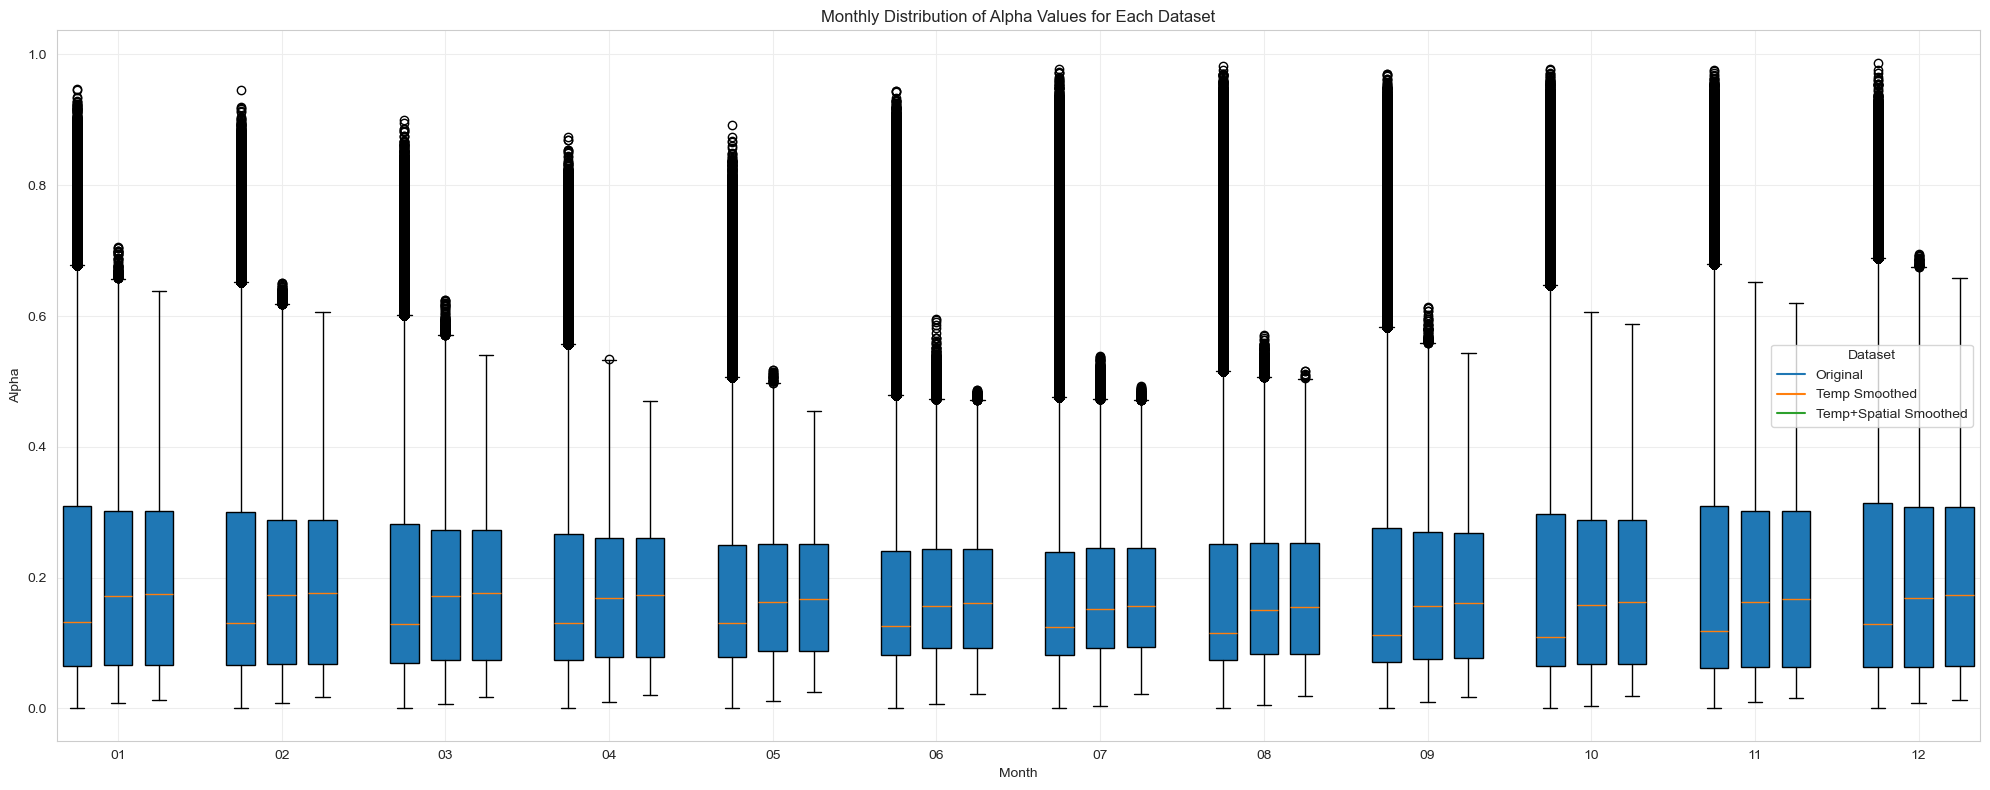

In [ ]:
# Prepare data for boxplot: extract alpha values for each month and dataset

months = np.arange(1, 13)
boxplot_data = []
boxplot_labels = []

for month in months:
    for label, ds in zip(
        ["Original", "Temp Smoothed", "Temp+Spatial Smoothed"],
        [
            da_alpha_cerra,
            da_alpha_temp_smoothed_cerra,
            da_alpha_tempspatial_smoothed_cerra,
        ],
    ):
        # Select all alpha values for the given month (across all years and grid points)
        month_mask = ds.time.dt.month == month
        alpha_vals = ds.alpha.sel(time=month_mask).values.ravel()
        # Remove NaNs
        alpha_vals = alpha_vals[~np.isnan(alpha_vals)]
        boxplot_data.append(alpha_vals)
        boxplot_labels.append(f"{label}\n{month:02d}")

plt.figure(figsize=(20, 8))
positions = []
for i in range(12):
    positions.extend([i * 4 + 1, i * 4 + 2, i * 4 + 3])
plt.boxplot(boxplot_data, positions=positions, widths=0.7, patch_artist=True)

# Set x-ticks in the center of each group of 3
plt.xticks([i * 4 + 2 for i in range(12)], [f"{month:02d}" for month in months])
plt.xlabel("Month")
plt.ylabel("Alpha")
plt.title("Monthly Distribution of Alpha Values for Each Dataset")
# Add legend manually
colors = ["C0", "C1", "C2"]
for i, color in enumerate(colors):
    plt.plot(
        [], c=color, label=["Original", "Temp Smoothed", "Temp+Spatial Smoothed"][i]
    )
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# Validate alpha computation

## 2025-07-16

In [ ]:
# Metrics for CERRA alpha extrapolation from 100m
df_cerra_100m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.0165, 0.0105, 0.0118],
    "mae": [0.2993, 0.3213, 0.3229],
    "mse": [0.2359, 0.2493, 0.2521],
    "rmse": [0.4857, 0.4993, 0.5021],
})

# Metrics for CERRA alpha extrapolation from 10m
df_cerra_10m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.2493, 0.2214, 0.23],
    "mae": [1.2178, 1.2643, 1.2671],
    "mse": [3.5216, 3.0992, 3.089],
    "rmse": [1.8766, 1.7604, 1.7576],
})

# Metrics for CORDEX alpha extrapolation from 10m
df_cordex_10m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.3354, 0.3106, 0.3149],
    "mae": [1.168, 1.1761, 1.1821],
    "mse": [3.2579, 2.6963, 2.6932],
    "rmse": [1.805, 1.642, 1.6411],
})

print("Metrics for CERRA alpha extrapolation from 100m, based on year 2021")
display(df_cerra_100m)
print("Metrics for CERRA alpha extrapolation from 10m, based on year 2021")
display(df_cerra_10m)
print("Metrics for CORDEX alpha extrapolation from 10m, based on year 2021-2030")
display(df_cordex_10m)

Metrics for CERRA alpha extrapolation from 100m, based on year 2021


,Method,bias,mae,mse,rmse
0,alpha,0.0165,0.2993,0.2359,0.4857
1,alpha_temp_smoothed,0.0105,0.3213,0.2493,0.4993
2,alpha_tempspatial_smoothed,0.0118,0.3229,0.2521,0.5021


Metrics for CERRA alpha extrapolation from 10m, based on year 2021


,Method,bias,mae,mse,rmse
0,alpha,0.2493,1.2178,3.5216,1.8766
1,alpha_temp_smoothed,0.2214,1.2643,3.0992,1.7604
2,alpha_tempspatial_smoothed,0.2300,1.2671,3.0890,1.7576


Metrics for CORDEX alpha extrapolation from 10m, based on year 2021-2030


,Method,bias,mae,mse,rmse
0,alpha,0.3354,1.1680,3.2579,1.8050
1,alpha_temp_smoothed,0.3106,1.1761,2.6963,1.6420
2,alpha_tempspatial_smoothed,0.3149,1.1821,2.6932,1.6411


In [4]:
# CERRA 10m -> 100m (2021)
df_cerra_10m_100m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.0939, 0.0922, 0.0983],
    "mae": [0.7966, 0.899, 0.9079],
    "mse": [1.6676, 1.6887, 1.7159],
    "rmse": [1.2914, 1.2995, 1.3099],
})

# CERRA 10m -> 150m (2021)
df_cerra_10m_150m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.1219, 0.1037, 0.1097],
    "mae": [1.0311, 1.1696, 1.1783],
    "mse": [2.751, 2.7755, 2.8087],
    "rmse": [1.6586, 1.666, 1.6759],
})

# CORDEX 10m -> 100m (2021-2030)
df_cordex_10m_100m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.1116, 0.1101, 0.1147],
    "mae": [0.7292, 0.7987, 0.8105],
    "mse": [1.3631, 1.2878, 1.3141],
    "rmse": [1.1675, 1.1348, 1.1463],
})

# CORDEX 10m -> 150m (2021-2030)
df_cordex_10m_150m = pd.DataFrame({
    "Method": ["alpha", "alpha_temp_smoothed", "alpha_tempspatial_smoothed"],
    "bias": [0.1407, 0.1276, 0.1311],
    "mae": [0.9541, 1.0496, 1.0612],
    "mse": [2.355, 2.224, 2.2531],
    "rmse": [1.5346, 1.4913, 1.501],
})

print("CERRA 10m -> 100m (2021)")
display(df_cerra_10m_100m)
print("CERRA 10m -> 150m (2021)")
display(df_cerra_10m_150m)
print("CORDEX 10m -> 100m (2021-2030)")
display(df_cordex_10m_100m)
print("CORDEX 10m -> 150m (2021-2030)")
display(df_cordex_10m_150m)

CERRA 10m -> 100m (2021)


,Method,bias,mae,mse,rmse
0,alpha,0.0939,0.7966,1.6676,1.2914
1,alpha_temp_smoothed,0.0922,0.8990,1.6887,1.2995
2,alpha_tempspatial_smoothed,0.0983,0.9079,1.7159,1.3099


CERRA 10m -> 150m (2021)


,Method,bias,mae,mse,rmse
0,alpha,0.1219,1.0311,2.7510,1.6586
1,alpha_temp_smoothed,0.1037,1.1696,2.7755,1.6660
2,alpha_tempspatial_smoothed,0.1097,1.1783,2.8087,1.6759


CORDEX 10m -> 100m (2021-2030)


,Method,bias,mae,mse,rmse
0,alpha,0.1116,0.7292,1.3631,1.1675
1,alpha_temp_smoothed,0.1101,0.7987,1.2878,1.1348
2,alpha_tempspatial_smoothed,0.1147,0.8105,1.3141,1.1463


CORDEX 10m -> 150m (2021-2030)


,Method,bias,mae,mse,rmse
0,alpha,0.1407,0.9541,2.3550,1.5346
1,alpha_temp_smoothed,0.1276,1.0496,2.2240,1.4913
2,alpha_tempspatial_smoothed,0.1311,1.0612,2.2531,1.5010
